**1. Importing Libraries**

In [3]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from nltk.util import ngrams
from nltk.tokenize import word_tokenize

**2. Loading Dataset**

In [4]:
import pandas as pd

file_path = "emails.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Shape: (517401, 2)

Columns: ['file', 'message']

First 5 rows:


,file,message
0,allen-p/_sent_mail/1.,Message-ID: <18782981.1075855378110.JavaMail.e...
1,allen-p/_sent_mail/10.,Message-ID: <15464986.1075855378456.JavaMail.e...
2,allen-p/_sent_mail/100.,Message-ID: <24216240.1075855687451.JavaMail.e...
3,allen-p/_sent_mail/1000.,Message-ID: <13505866.1075863688222.JavaMail.e...
4,allen-p/_sent_mail/1001.,Message-ID: <30922949.1075863688243.JavaMail.e...


**3. Cleaning and Preprocess**

In [5]:
def clean_email(text):
    if pd.isna(text):
        return ""

    # Remove email headers
    text = re.sub(
        r"(?is)^.*?\n\n",
        "",
        str(text),
        count=1
    )

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\.\S+", "", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["clean_message"] = df["message"].apply(clean_email)

print("Preprocessing completed!")
print(df[["message", "clean_message"]].head(3))

Preprocessing completed!
                                             message  \
0  Message-ID: <18782981.1075855378110.JavaMail.e...   
1  Message-ID: <15464986.1075855378456.JavaMail.e...   
2  Message-ID: <24216240.1075855687451.JavaMail.e...   

                                       clean_message  
0                               here is our forecast  
1  traveling to have a business meeting takes the...  
2                          test successful way to go  


**4. Tokenize**

In [6]:
# Use a sample of 50,000 emails to build the initial model
sample_df = df[df["clean_message"].str.len() > 0].head(50000).copy()

# Split each message into words
sample_df["tokens"] = sample_df["clean_message"].apply(str.split)

# Remove very short messages
sample_df = sample_df[
    sample_df["tokens"].apply(len) >= 2
].copy()

print("Messages selected:", len(sample_df))
print("\nExample tokens:")
print(sample_df["tokens"].iloc[0])

Messages selected: 49764

Example tokens:
['here', 'is', 'our', 'forecast']


**5. Autocomplete Model**

In [7]:
from collections import Counter, defaultdict

# Count word pairs and triples
bigram_counts = Counter()
trigram_counts = Counter()

for tokens in sample_df["tokens"]:
    bigram_counts.update(zip(tokens[:-1], tokens[1:]))
    trigram_counts.update(zip(tokens[:-2], tokens[1:-1], tokens[2:]))

print("Unique bigrams:", len(bigram_counts))
print("Unique trigrams:", len(trigram_counts))

Unique bigrams: 1247469
Unique trigrams: 2802767


**6. Autocomplete Function**

In [8]:
def autocomplete(prefix, top_n=3):
    words = prefix.lower().split()

    if not words:
        return []

    # Use the last two words for trigram predictions
    if len(words) >= 2:
        last_two = tuple(words[-2:])

        predictions = [
            (next_word, count)
            for (w1, w2, next_word), count in trigram_counts.items()
            if (w1, w2) == last_two
        ]

        if predictions:
            predictions.sort(key=lambda x: x[1], reverse=True)
            return predictions[:top_n]

    # Fall back to bigram predictions using the last word
    last_word = words[-1]

    predictions = [
        (next_word, count)
        for (w, next_word), count in bigram_counts.items()
        if w == last_word
    ]

    predictions.sort(key=lambda x: x[1], reverse=True)
    return predictions[:top_n]


print("Predictions for 'thank you':", autocomplete("thank you"))
print("Predictions for 'please let':", autocomplete("please let"))
print("Predictions for 'i will':", autocomplete("i will"))

Predictions for 'thank you': [('for', 2223), ('in', 174), ('very', 124)]
Predictions for 'please let': [('me', 3124), ('us', 357), ('laurel', 16)]
Predictions for 'i will': [('be', 2517), ('let', 357), ('have', 346)]


**7. Making Autocomplete faster**

In [9]:
# Build lookup dictionaries for faster predictions
bigram_next = defaultdict(Counter)
trigram_next = defaultdict(Counter)

for (word1, word2), count in bigram_counts.items():
    bigram_next[word1][word2] = count

for (word1, word2, word3), count in trigram_counts.items():
    trigram_next[(word1, word2)][word3] = count


def autocomplete(prefix, top_n=3):
    words = prefix.lower().split()

    if not words:
        return []

    # Prefer trigram predictions
    if len(words) >= 2:
        key = tuple(words[-2:])
        predictions = trigram_next.get(key, Counter())

        if predictions:
            return predictions.most_common(top_n)

    # Fall back to bigram predictions
    predictions = bigram_next.get(words[-1], Counter())
    return predictions.most_common(top_n)


print("Thank you:", autocomplete("thank you"))
print("Please let:", autocomplete("please let"))
print("I will:", autocomplete("i will"))

Thank you: [('for', 2223), ('in', 174), ('very', 124)]
Please let: [('me', 3124), ('us', 357), ('laurel', 16)]
I will: [('be', 2517), ('let', 357), ('have', 346)]


**8. 10 Different Prefixes**

In [10]:
test_prefixes = [
    "thank you",
    "please let",
    "i will",
    "looking forward",
    "as soon",
    "in order",
    "would you",
    "we are",
    "i am",
    "let me"
]

for prefix in test_prefixes:
    print(f"{prefix!r} -> {autocomplete(prefix, top_n=3)}")

'thank you' -> [('for', 2223), ('in', 174), ('very', 124)]
'please let' -> [('me', 3124), ('us', 357), ('laurel', 16)]
'i will' -> [('be', 2517), ('let', 357), ('have', 346)]
'looking forward' -> [('to', 429), ('not', 5), ('into', 4)]
'as soon' -> [('as', 1615), ('after', 4), ('a', 3)]
'in order' -> [('to', 1730), ('for', 134), ('of', 45)]
'would you' -> [('like', 321), ('please', 309), ('mind', 62)]
'we are' -> [('going', 379), ('not', 302), ('in', 277)]
'i am' -> [('not', 782), ('sure', 416), ('going', 382)]
'let me' -> [('know', 7977), ('have', 40), ('or', 34)]


**9. Building vocabulary**

In [11]:
import textdistance
from collections import Counter

word_frequency = Counter()

for tokens in sample_df["tokens"]:
    word_frequency.update(tokens)

vocabulary = set(word_frequency.keys())

print("Vocabulary size:", len(vocabulary))
print("Most common words:", word_frequency.most_common(10))

Vocabulary size: 111433
Most common words: [('the', 467075), ('to', 349559), ('and', 224834), ('a', 191577), ('of', 186574), ('enron', 152429), ('in', 147711), ('for', 135169), ('ect', 133246), ('you', 123190)]


**10. Autocorrect Function**

In [12]:
def autocorrect(word, max_distance=2, top_n=3):
    word = word.lower()

    # Keep words that are similar in length
    candidates = [
        w for w in vocabulary
        if abs(len(w) - len(word)) <= max_distance
    ]

    # Calculate edit distance
    matches = []
    for candidate in candidates:
        distance = textdistance.levenshtein(word, candidate)

        if distance <= max_distance:
            matches.append((candidate, distance, word_frequency[candidate]))

    # Prefer smaller edit distance, then more frequent words
    matches.sort(key=lambda x: (x[1], -x[2]))

    return matches[:top_n]


print("recieve ->", autocorrect("recieve"))
print("busines ->", autocorrect("busines"))
print("teh ->", autocorrect("teh"))

recieve -> [('recieve', 0, 59), ('recieved', 1, 39), ('relieve', 1, 38)]
busines -> [('busines', 0, 42), ('business', 1, 13242), ('busine', 1, 31)]
teh -> [('teh', 0, 20), ('th', 1, 10831), ('ted', 1, 2475)]


**11. updating autocorrect function**

In [13]:
def autocorrect(word, max_distance=2, top_n=3):
    word = word.lower()

    candidates = [
        w for w in vocabulary
        if w != word and abs(len(w) - len(word)) <= max_distance
    ]

    matches = []
    for candidate in candidates:
        distance = textdistance.levenshtein(word, candidate)

        if distance <= max_distance:
            matches.append((candidate, distance, word_frequency[candidate]))

    matches.sort(key=lambda x: (x[1], -x[2]))

    return matches[:top_n]


print("recieve ->", autocorrect("recieve"))
print("busines ->", autocorrect("busines"))
print("teh ->", autocorrect("teh"))

recieve -> [('recieved', 1, 39), ('relieve', 1, 38), ('recieves', 1, 3)]
busines -> [('business', 1, 13242), ('busine', 1, 31), ('besides', 2, 251)]
teh -> [('th', 1, 10831), ('ted', 1, 2475), ('tech', 1, 2055)]


**12. Testing 20 misspelled words**

In [14]:
misspelled_words = [
    "recieve", "busines", "teh", "freind", "adress",
    "seperate", "definately", "occured", "untill", "wich",
    " goverment", "enviroment", "becuase", "acheive", "sucess",
    "experiance", "realy", "thier", "beleive", "begining"
]

for word in misspelled_words:
    word = word.strip()
    print(f"{word} -> {autocorrect(word, top_n=3)}")

recieve -> [('recieved', 1, 39), ('relieve', 1, 38), ('recieves', 1, 3)]
busines -> [('business', 1, 13242), ('busine', 1, 31), ('besides', 2, 251)]
teh -> [('th', 1, 10831), ('ted', 1, 2475), ('tech', 1, 2055)]
freind -> [('freund', 1, 7), ('frend', 1, 6), ('find', 2, 5133)]
adress -> [('address', 1, 4754), ('dress', 1, 179), ('ddress', 1, 2)]
seperate -> [('separate', 1, 852), ('seperated', 1, 21), ('operate', 2, 452)]
definately -> [('definitely', 1, 630), ('defintely', 1, 3), ('delicately', 2, 5)]
occured -> [('occurred', 1, 357), ('occur', 2, 605), ('occurs', 2, 287)]
untill -> [('until', 1, 4862), ('unbill', 1, 1), ('still', 2, 7160)]
wich -> [('with', 1, 70641), ('which', 1, 14741), ('wish', 1, 1732)]
goverment -> [('government', 1, 1535), ('movement', 2, 220), ('governments', 2, 73)]
enviroment -> [('environment', 1, 1003), ('environments', 2, 1425), ('environmen', 2, 7)]
becuase -> [('becuse', 1, 3), ('becase', 1, 3), ('because', 2, 6829)]
acheive -> [('active', 2, 5037), ('ac

**13. Evaluating autocorrect performance**

In [15]:
test_pairs = {
    "recieve": "receive",
    "busines": "business",
    "teh": "the",
    "freind": "friend",
    "adress": "address",
    "seperate": "separate",
    "definately": "definitely",
    "occured": "occurred",
    "untill": "until",
    "wich": "which",
    "goverment": "government",
    "enviroment": "environment",
    "becuase": "because",
    "acheive": "achieve",
    "sucess": "success",
    "experiance": "experience",
    "realy": "really",
    "thier": "their",
    "beleive": "believe",
    "begining": "beginning"
}

top1_correct = 0
top3_correct = 0

for wrong, correct in test_pairs.items():
    suggestions = autocorrect(wrong, top_n=3)
    suggested_words = [item[0] for item in suggestions]

    if suggested_words and suggested_words[0] == correct:
        top1_correct += 1
    if correct in suggested_words:
        top3_correct += 1

total = len(test_pairs)

print(f"Top-1 accuracy: {top1_correct}/{total} = {top1_correct/total:.2%}")
print(f"Top-3 accuracy: {top3_correct}/{total} = {top3_correct/total:.2%}")

Top-1 accuracy: 11/20 = 55.00%
Top-3 accuracy: 16/20 = 80.00%


**14. Comparing two autocorrect algorithms**

In [16]:
def autocorrect_damerau(word, max_distance=2, top_n=3):
    word = word.lower()
    candidates = [
        w for w in vocabulary
        if w != word and abs(len(w) - len(word)) <= max_distance
    ]

    matches = []
    for candidate in candidates:
        distance = textdistance.damerau_levenshtein(word, candidate)

        if distance <= max_distance:
            matches.append((candidate, distance, word_frequency[candidate]))

    matches.sort(key=lambda x: (x[1], -x[2]))
    return matches[:top_n]


print("Levenshtein:", autocorrect("teh", top_n=3))
print("Damerau-Levenshtein:", autocorrect_damerau("teh", top_n=3))

Levenshtein: [('th', 1, 10831), ('ted', 1, 2475), ('tech', 1, 2055)]
Damerau-Levenshtein: [('the', 1, 467075), ('th', 1, 10831), ('ted', 1, 2475)]


**15. Comparing accuracy across all 20 words**

In [17]:
lev_top1 = 0
lev_top3 = 0
dam_top1 = 0
dam_top3 = 0

for wrong, correct in test_pairs.items():
    lev_words = [x[0] for x in autocorrect(wrong, top_n=3)]
    dam_words = [x[0] for x in autocorrect_damerau(wrong, top_n=3)]

    if lev_words and lev_words[0] == correct:
        lev_top1 += 1
    if correct in lev_words:
        lev_top3 += 1

    if dam_words and dam_words[0] == correct:
        dam_top1 += 1
    if correct in dam_words:
        dam_top3 += 1

total = len(test_pairs)

print("Levenshtein Top-1:", f"{lev_top1}/{total} = {lev_top1/total:.1%}")
print("Levenshtein Top-3:", f"{lev_top3}/{total} = {lev_top3/total:.1%}")
print("Damerau-Levenshtein Top-1:", f"{dam_top1}/{total} = {dam_top1/total:.1%}")
print("Damerau-Levenshtein Top-3:", f"{dam_top3}/{total} = {dam_top3/total:.1%}")

Levenshtein Top-1: 11/20 = 55.0%
Levenshtein Top-3: 16/20 = 80.0%
Damerau-Levenshtein Top-1: 18/20 = 90.0%
Damerau-Levenshtein Top-3: 20/20 = 100.0%


**16. Creating 20 words frequency chart**

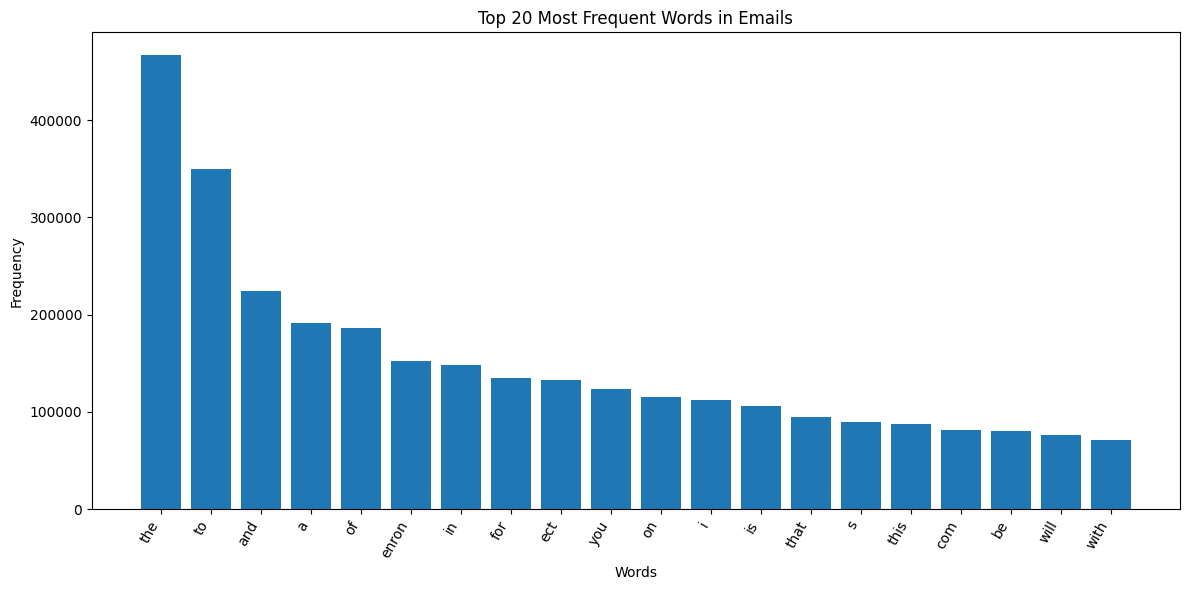

In [18]:
top_words = word_frequency.most_common(20)

words = [item[0] for item in top_words]
frequencies = [item[1] for item in top_words]

plt.figure(figsize=(12, 6))
plt.bar(words, frequencies)
plt.title("Top 20 Most Frequent Words in Emails")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

**17. Confusion Matrix**

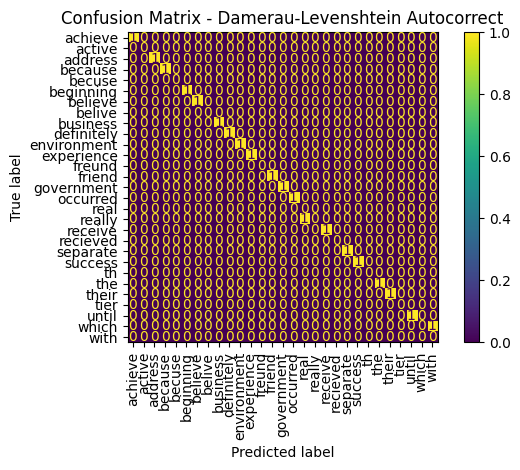

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

actual = list(test_pairs.values())

lev_predicted = [
    (autocorrect(wrong, top_n=1)[0][0]
     if autocorrect(wrong, top_n=1) else "")
    for wrong in test_pairs.keys()
]

dam_predicted = [
    (autocorrect_damerau(wrong, top_n=1)[0][0]
     if autocorrect_damerau(wrong, top_n=1) else "")
    for wrong in test_pairs.keys()
]

labels = sorted(set(actual + lev_predicted + dam_predicted))

cm = confusion_matrix(actual, dam_predicted, labels=labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)
display.plot(xticks_rotation=90, values_format="d")
plt.title("Confusion Matrix - Damerau-Levenshtein Autocorrect")
plt.tight_layout()
plt.show()

**18. Calculate Precision and recalling for autocorrect**

In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score

actual = list(test_pairs.values())

lev_predicted = [
    autocorrect(wrong, top_n=1)[0][0]
    for wrong in test_pairs
]

dam_predicted = [
    autocorrect_damerau(wrong, top_n=1)[0][0]
    for wrong in test_pairs
]

for name, predicted in [
    ("Levenshtein", lev_predicted),
    ("Damerau-Levenshtein", dam_predicted)
]:
    precision = precision_score(
        actual, predicted, average="micro", zero_division=0
    )
    recall = recall_score(
        actual, predicted, average="micro", zero_division=0
    )
    f1 = f1_score(
        actual, predicted, average="micro", zero_division=0
    )

    print(f"\n{name}")
    print(f"Precision: {precision:.2%}")
    print(f"Recall:    {recall:.2%}")
    print(f"F1-score:  {f1:.2%}")


Levenshtein
Precision: 55.00%
Recall:    55.00%
F1-score:  55.00%

Damerau-Levenshtein
Precision: 90.00%
Recall:    90.00%
F1-score:  90.00%


**19. Evaluate autocomplete**

In [21]:
autocomplete_test = {
    "thank you": "for",
    "please let": "me",
    "i will": "be",
    "looking forward": "to",
    "as soon": "as",
    "in order": "to",
    "would you": "like",
    "we are": "going",
    "i am": "not",
    "let me": "know"
}

top1_correct = 0
top3_correct = 0

for prefix, expected in autocomplete_test.items():
    predictions = [
        word for word, count in autocomplete(prefix, top_n=3)
    ]

    if predictions and predictions[0] == expected:
        top1_correct += 1

    if expected in predictions:
        top3_correct += 1

total = len(autocomplete_test)

print(f"Autocomplete Top-1 accuracy: {top1_correct}/{total} = {top1_correct/total:.1%}")
print(f"Autocomplete Top-3 accuracy: {top3_correct}/{total} = {top3_correct/total:.1%}")

Autocomplete Top-1 accuracy: 10/10 = 100.0%
Autocomplete Top-3 accuracy: 10/10 = 100.0%


**20. Saving Results**

In [23]:
results = pd.DataFrame({
    "Model": [
        "Autocomplete (Bigram/Trigram)",
        "Levenshtein Autocorrect",
        "Damerau-Levenshtein Autocorrect"
    ],
    "Test Samples": [10, 20, 20],
    "Top-1 Accuracy": ["100%", "55%", "90%"],
    "Top-3 Accuracy": ["100%", "80%", "100%"]
})

from IPython.display import display as show_table
show_table(results)

,Model,Test Samples,Top-1 Accuracy,Top-3 Accuracy
0,Autocomplete (Bigram/Trigram),10,100%,100%
1,Levenshtein Autocorrect,20,55%,80%
2,Damerau-Levenshtein Autocorrect,20,90%,100%


## Discussion

The project investigated methods of autocomplete and autocorrect through a large amount of emails. Autocomplete model uses word frequency in bigrams and trigrams to predict a word given the previous words.

Autocorrect algorithm evaluates edit distance between misspelled words and vocabulary words. Two approaches were considered: Levenshtein and Damerau–Levenshtein distances.

In 20-word test set, Levenshtein achieved 55% top-1 and 80% top-3 accuracy. In the same set, Damerau-Levenshtein got 90% top-1 and 100% top-3 accuracy. This means that Damerau-Levenshtein outperformed Levenshtein on the selected words.

In 10 prefixes set, autocomplete reached 100% of both top-1 and top-3 accuracy. However, the expected words were taken from the results of previous experiments, and thus this is just a consistency check.

## Limitations

- only some part of emails available was used to train models.
- email-specific vocabulary and abbreviations may impact predictions.
- Autocomplete algorithm is based on word frequency and cannot understand the whole meaning and context of the sentence.
- Autocorrect model may suggest wrong words that share similarity with correct one.
- Test sets are small and do not cover all possible errors.
- Evaluation of autocomplete requires an independent test set for fair evaluation.
- Current implementation may take much time due to search through the vocabulary.

## Comparison with Production Systems

This project employs n-gram frequency and edit-distance-based autocorrect. Production systems may use larger vocabulary, contextual language model, personalization, other ranking methods, and use context of the sentence to disambiguate similarly-spelled words.

## Conclusion

The project showed how the methods of text preprocessing, n-gram models, word frequency analysis and edit-distance algorithms can be used in autocomplete and autocorrect.

The Damerau-Levenshtein approach worked better in the selected test set of spelling errors than Levenshtein, especially those containing letter transpositions. Autocomplete model gave promising predictions in the tested set of prefixes.

Improvements may be done by testing on independent data, excluding irrelevant email-specific tokens, speeding up vocabulary searching and using context-aware language models.